# Análise de sentimento em avaliações de e-commerce — EDA e pré-processamento

**Disciplina:** Machine Learning — Trabalho final
**Dupla:** Guilherme Theis e Paulo Henrique

**Tarefa:** classificação de sentimento em 3 classes (negativo / neutro / positivo) a partir do texto
de avaliações de produtos em português.

| | |
|---|---|
| **Entrada** | título + texto da avaliação (`review_title` + `review_text`) |
| **Saída** | sentimento derivado da nota `overall_rating`: 1–2 → negativo, 3 → neutro, 4–5 → positivo |
| **Modelo (próxima etapa)** | BERTimbau (`neuralmind/bert-base-portuguese-cased`) com *fine-tuning* |
| **Baseline** | TF-IDF + regressão logística |
| **Métrica principal** | F1-macro (as classes são desbalanceadas) |
| **Dados** | corpus **B2W-Reviews01** (Americanas.com, jan–mai/2018), licença CC BY-NC-SA 4.0 |

> **Sobre a mudança de base.** O plano inicial era classificar reclamações do Consumidor.gov.br.
> Ao inspecionar os dados abertos, verificamos que eles **não trazem o texto do relato**, só campos
> categóricos (Área, Assunto, Grupo Problema, Problema etc.), e que os links de download no
> dados.gov.br estão quebrados (o domínio `dados.mj.gov.br` deixou de existir). Sem texto livre não há
> como treinar um modelo de linguagem, então trocamos para o B2W-Reviews01. Detalhes no README.

**Roteiro deste notebook**

1. Carga dos dados e anonimização
2. Análise exploratória (EDA)
3. Limpeza (funil)
4. Normalização do texto e encoding dos rótulos
5. Divisão temporal em treino / validação / teste
6. Ajustes feitos só no treino: TF-IDF, pesos de classe, e o teste "o título ajuda?"
7. Data augmentation: avaliar se vale a pena
8. Tokenização com o BERTimbau e escolha do `max_length`
9. Salvamento dos conjuntos e resumo final

Toda a lógica está em funções pequenas na pasta `src/`; este notebook importa essas funções e registra
as decisões.

In [1]:
import json
import os
import sys
import warnings

# Silencia avisos irrelevantes da biblioteca transformers/huggingface_hub (PyTorch ausente, barras de progresso)
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Raiz do projeto (o notebook pode ser executado de notebooks/ ou da raiz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.download import download
from src.anonymize import REVIEWER_COLUMNS, drop_reviewer_columns, mask_pii_columns
from src.clean import (
    SENTIMENT_LABELS, STOPWORDS_PT, CleaningFunnel, build_input, contradictory_mask, count_words,
    has_mojibake, mask_conflicting_duplicates, normalize_text, rating_to_sentiment, text_for_tfidf,
)
from src.split import class_weights_from_train, save_json, split_summary, temporal_split
from src.augment import augment_minority, eda_augment

FIG_DIR = ROOT / "reports" / "figures"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)

# Estilo dos gráficos: fundo claro, eixos e grade discretos, marcas finas.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE = "#2a78d6"
# Sentimento é uma escala de polaridade: vermelho (negativo) ↔ cinza neutro ↔ azul (positivo).
CLASS_COLORS = {"negativo": "#e34948", "neutro": "#8c8b86", "positivo": "#2a78d6"}
RATING_COLORS = {1: "#c23b3b", 2: "#ee8e8d", 3: "#8c8b86", 4: "#86b6ef", 5: "#1c5cab"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})


def savefig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figura salva em reports/figures/{path.name}")


def fmt_int(x):
    return f"{x:,.0f}".replace(",", ".")

## 1. Carga dos dados e anonimização

O arquivo é baixado por `src/download.py` de um **commit fixo** do repositório oficial
(`americanas-tech/b2w-reviews01`) e conferido por SHA-256: qualquer pessoa que rode o projeto obtém
exatamente os mesmos dados.

In [2]:
raw_path = download()
raw = pd.read_csv(raw_path, low_memory=False)
print("Formato original:", raw.shape)
print("Colunas:", list(raw.columns))

Arquivo já existe e confere com o SHA-256: data\raw\B2W-Reviews01.csv
Formato original: (132373, 14)
Colunas: ['submission_date', 'reviewer_id', 'product_id', 'product_name', 'product_brand', 'site_category_lv1', 'site_category_lv2', 'review_title', 'overall_rating', 'recommend_to_a_friend', 'review_text', 'reviewer_birth_year', 'reviewer_gender', 'reviewer_state']


### 1.1 Remoção das colunas do avaliador

O corpus traz o perfil de quem escreveu a avaliação: `reviewer_id` (hash), ano de nascimento, gênero e
estado. **Nenhuma dessas colunas é necessária para a tarefa** (prever o sentimento a partir do texto).
Mantê-las só aumentaria o risco de reidentificação e de o modelo aprender vieses demográficos. Por isso
elas são descartadas **antes de qualquer análise**.

In [3]:
df = drop_reviewer_columns(raw)
print("Colunas removidas:", [c for c in REVIEWER_COLUMNS if c in raw.columns])
print("Formato após remoção:", df.shape)
del raw
df.head(3)

Colunas removidas: ['reviewer_id', 'reviewer_birth_year', 'reviewer_gender', 'reviewer_state']
Formato após remoção: (132373, 10)


,submission_date,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text
0,2018-01-01 00:11:28,132532965,"Notebook Asus Vivobook Max X541NA-GO472T Intel Celeron Quad Core 4GB 500GB Tela LED 15,6"" Windows - 10 Branco",NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o único problema com as Americanas é se houver troca ou devolução do produto o consumidor tem problemas com espera.
1,2018-01-01 00:13:48,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse lindo copo de acrílico."
2,2018-01-01 00:26:02,113022329,Panela de Pressão Elétrica Philips Walita Daily 5L com Timer,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,"SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANELAS ELÉTRICAS. COSTUMO USAR OUTRA PANELA PARA COZIMENTO DE ARROZ (JAPONESA), MAS LEVA MUITO TEMPO, +/- 50 MINUTOS. NESSA PANELA É MUITO MAIS RÁPIDO..."


### 1.2 Mascaramento de dados pessoais no texto

Mesmo sem as colunas de perfil, o próprio texto pode conter dados pessoais. Aplicamos expressões
regulares (em `src/anonymize.py`) que trocam cada ocorrência por um marcador:

| Tipo | Exemplo de padrão | Marcador |
|---|---|---|
| e-mail | `nome@dominio.com` | `[EMAIL]` |
| CPF | `123.456.789-00` | `[CPF]` |
| CNPJ | `12.345.678/0001-90` | `[CNPJ]` |
| telefone | `(11) 91234-5678`, `3333-4444` | `[TELEFONE]` |
| CEP | `01310-100` | `[CEP]` |
| código de rastreio dos Correios | `PP123456789BR` | `[RASTREIO]` |
| URL | `https://...`, `www...` | `[URL]` |

Os padrões exigem a formatação típica de cada dado, para não mascarar por engano preços
(`R$ 1.299,90`), modelos de produto ou notas. O código de rastreio entra porque identifica a encomenda
e, portanto, o destinatário. As URLs não são dados pessoais, mas são ruído para o modelo e podem
apontar para perfis pessoais.

In [4]:
df, pii_report = mask_pii_columns(df, ["review_title", "review_text"])
print("Ocorrências mascaradas por tipo:")
display(pii_report)

masked = df[df["review_text"].str.contains(r"\[(?:EMAIL|CPF|CNPJ|TELEFONE|CEP|RASTREIO|URL)\]", na=False, regex=True)]
print(f"Avaliações com pelo menos um marcador: {len(masked)}")
display(masked[["review_text"]].head(4))

Ocorrências mascaradas por tipo:


,EMAIL,URL,CNPJ,CPF,CEP,TELEFONE,RASTREIO
coluna,,,,,,,
review_title,0,1,0,0,0,0,0
review_text,0,86,1,0,0,0,4
total,0,87,1,0,0,0,4


Avaliações com pelo menos um marcador: 90


,review_text
951,"1) A código da nota fiscal segundo o site da fazenda (link) necessita de 44 números e o informado por vcs via e-mail possui 40, portanto não consegui visualizar a NF. 2) A máquina em questão não ..."
2568,Amei o produto....comprem Se você é daqueles que lê os comentários eu tbm faço isso por isso comprei :) Eu ia pagar para montarem Porem meu marido seguiu o passo a passo pelo Youtube e pela primei...
5806,"é lamentável que uma empresa conhecida e conceituada como a Americanas tenha um fornecedor de uma ínfima reputação, como a Forthouse, basta acessar o site: ""[URL] para se certificar disto. Não rec..."
9365,"Olha vocês das Lojas Americanas estão mais... muito... muito mesmo por fora de games. Nos games respiramos jogos. E ver um anuncio desses, é burrices Lojas Americanas . Quem na sua sã consciênci..."


**Leitura:** o corpus praticamente não tem dados pessoais no texto. Não há e-mails nem CPFs, e só
aparecem um CNPJ (de empresa), alguns códigos de rastreio e algumas URLs. Isso é coerente com uma
base pública de avaliações que, ao que tudo indica, já passou por moderação. O mascaramento continua
no pipeline como salvaguarda: aplicado a outra base ou a dados novos, ele pega esses casos.

## 2. Análise exploratória (EDA)

### 2.1 Visão geral, tipos e valores nulos

In [5]:
df["submission_date"] = pd.to_datetime(df["submission_date"])
df["product_id"] = df["product_id"].astype(str)

overview = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (100 * df.isna().mean()).round(2),
    "valores distintos": df.nunique(),
})
display(overview)
print(f"Período coberto: {df['submission_date'].min():%d/%m/%Y} a {df['submission_date'].max():%d/%m/%Y}")

,tipo,nulos,% nulos,valores distintos
submission_date,datetime64[us],0,0.00,129927
product_id,str,0,0.00,48001
product_name,str,84,0.06,47363
product_brand,str,91391,69.04,1062
site_category_lv1,str,6,0.00,54
site_category_lv2,str,4013,3.03,713
review_title,str,302,0.23,56555
overall_rating,int64,0,0.00,5
recommend_to_a_friend,str,18,0.01,2
review_text,str,3275,2.47,126724


Período coberto: 01/01/2018 a 31/05/2018


- `review_text` tem cerca de 3,3 mil nulos (2,5%). Sem o texto a avaliação não serve para a tarefa
  (o título sozinho é curto demais), então essas linhas serão removidas.
- `review_title` tem cerca de 300 nulos. Como o título é só um complemento, eles viram string vazia.
- `recommend_to_a_friend` tem 18 nulos. Removemos essas linhas, porque a coluna é usada na checagem
  de consistência dos rótulos.
- `product_brand` está vazia em cerca de 70% das linhas e `site_category_lv2` em cerca de 3%. Elas
  não entram no modelo e servem só para a EDA.

### 2.2 Volume de avaliações por mês

figura salva em reports/figures/01_volume_mensal.png


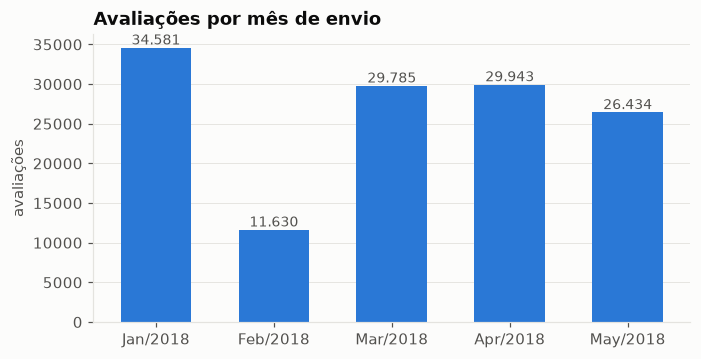

In [6]:
monthly = df.groupby(df["submission_date"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(monthly.index.strftime("%b/%Y"), monthly.values, color=BLUE, width=0.6)
for x, v in zip(range(len(monthly)), monthly.values):
    ax.text(x, v, fmt_int(v), ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_title("Avaliações por mês de envio")
ax.set_ylabel("avaliações")
ax.grid(axis="x", visible=False)
savefig(fig, "01_volume_mensal")
plt.show()

O corpus cobre só **5 meses** (jan–mai/2018). Fevereiro tem cerca de um terço do volume dos outros
meses. A documentação do corpus não explica a queda, então não a interpretamos. O efeito prático é que
a divisão temporal deve ser feita com cortes por data, e não por mês inteiro (seção 5). O volume diário
é alto o bastante para isso.

### 2.3 Distribuição da nota original e das 3 classes

figura salva em reports/figures/02_distribuicao_notas_e_classes.png


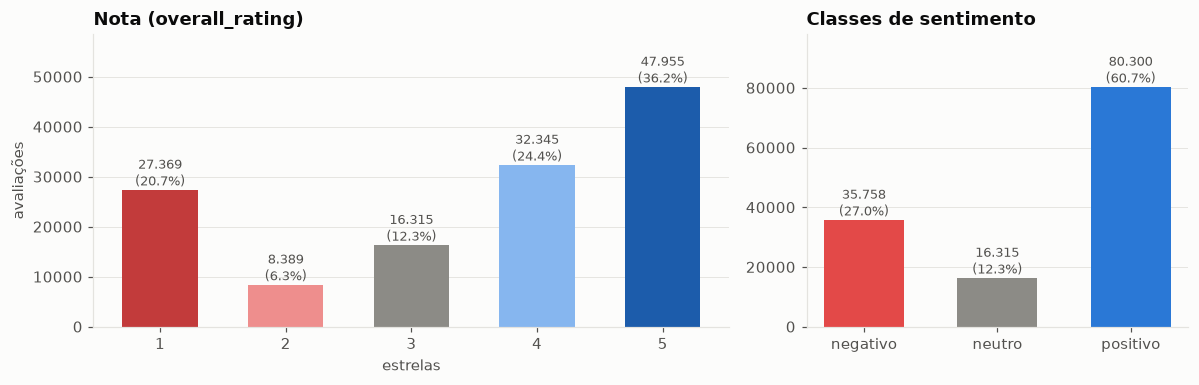

,avaliações,%
label,,
negativo,35758,27.0
neutro,16315,12.3
positivo,80300,60.7


Razão maior/menor classe: 4.9x


In [7]:
df["label"] = df["overall_rating"].map(rating_to_sentiment)

rating_counts = df["overall_rating"].value_counts().sort_index()
class_counts = df["label"].value_counts().reindex(SENTIMENT_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [5, 3]})
ax = axes[0]
ax.bar(rating_counts.index.astype(str), rating_counts.values,
       color=[RATING_COLORS[r] for r in rating_counts.index], width=0.6)
for x, v in enumerate(rating_counts.values):
    ax.text(x, v, f"{fmt_int(v)}\n({100 * v / rating_counts.sum():.1f}%)", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_title("Nota (overall_rating)")
ax.set_xlabel("estrelas"); ax.set_ylabel("avaliações"); ax.set_ylim(0, rating_counts.max() * 1.22)
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.bar(class_counts.index, class_counts.values, color=[CLASS_COLORS[c] for c in class_counts.index], width=0.6)
for x, v in enumerate(class_counts.values):
    ax.text(x, v, f"{fmt_int(v)}\n({100 * v / class_counts.sum():.1f}%)", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_title("Classes de sentimento")
ax.set_ylim(0, class_counts.max() * 1.22)
ax.grid(axis="x", visible=False)
fig.tight_layout()
savefig(fig, "02_distribuicao_notas_e_classes")
plt.show()

display(pd.DataFrame({"avaliações": class_counts, "%": (100 * class_counts / class_counts.sum()).round(1)}))
print(f"Razão maior/menor classe: {class_counts.max() / class_counts.min():.1f}x")

**Desbalanceamento:** a classe **positivo** tem cerca de 60% dos exemplos, **negativo** cerca de 27% e
**neutro** só cerca de 12%, quase 5 vezes menos que a majoritária. A distribuição das notas é em "U"
(muitas notas 1 e 5, poucas 2 e 3), padrão comum em avaliações on-line: as pessoas tendem a avaliar
quando estão muito satisfeitas ou muito insatisfeitas.

Consequências:

- a **acurácia** seria enganosa (um modelo que só diz "positivo" acerta cerca de 60%), por isso a
  métrica principal é o **F1-macro**, que dá o mesmo peso às três classes;
- o **neutro** deve ser a classe mais difícil: tem poucos exemplos e fica entre as outras duas. É o
  alvo natural de pesos de classe (seção 6) e, se fizer sentido, de *augmentation* (seção 7).

Sobre a regra de agrupar em "Outros" as classes com menos de ~1% dos dados: **ela não se aplica aqui**.
São só 3 classes e a menor tem mais de 10% da base.

### 2.4 Consistência dos rótulos: nota × "recomendaria a um amigo"

A coluna `recommend_to_a_friend` (Yes/No) é um segundo sinal, independente, do mesmo julgamento.
Cruzá-la com a nota ajuda a estimar o **ruído nos rótulos**.

figura salva em reports/figures/03_nota_vs_recomendacao.png


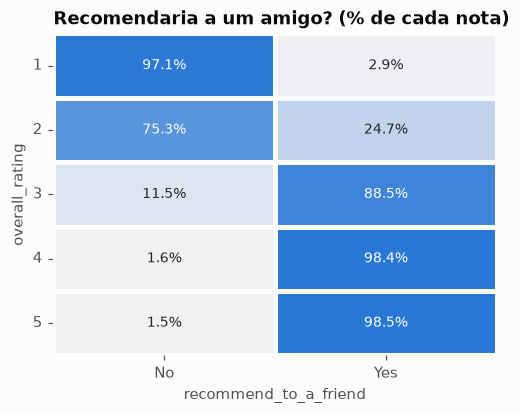

recommend_to_a_friend,No,Yes
overall_rating,,
1,26574,795
2,6321,2068
3,1879,14434
4,508,31837
5,705,47234


In [8]:
ct = pd.crosstab(df["overall_rating"], df["recommend_to_a_friend"])
ct_pct = pd.crosstab(df["overall_rating"], df["recommend_to_a_friend"], normalize="index").mul(100)

fig, ax = plt.subplots(figsize=(5.2, 3.8))
sns.heatmap(ct_pct[["No", "Yes"]], annot=ct_pct[["No", "Yes"]].map(lambda v: f"{v:.1f}%"), fmt="",
            cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False, linewidths=2, linecolor=SURFACE, ax=ax,
            annot_kws={"fontsize": 9})
ax.set_title("Recomendaria a um amigo? (% de cada nota)")
ax.set_xlabel("recommend_to_a_friend"); ax.set_ylabel("overall_rating")
ax.tick_params(axis="y", rotation=0)
savefig(fig, "03_nota_vs_recomendacao")
plt.show()
display(ct)

A relação é a esperada: nota 1 tem 97% de "No", nota 5 tem 98,5% de "Yes", e a nota 3 (neutro) já
pende para "Yes" (88%). Há duas zonas de inconsistência:

- **Notas 2 e 4 contraditas** (por exemplo, nota 2 com "Yes": 25% das notas 2). São casos ambíguos de
  verdade (o produto é "mais ou menos"), e a própria escala deixa margem para isso.
- **Notas extremas contraditas**: nota **1 com "Yes"** (795) e nota **5 com "No"** (705). Aqui os dois
  sinais apontam para lados opostos com intensidade máxima. A pergunta que importa é: **qual dos dois
  sinais está errado?** Se for a nota, nosso rótulo está errado e a linha deve sair. Se for a
  recomendação, que não usamos, o rótulo está certo. Lemos uma amostra aleatória de 25 casos de cada
  tipo:

In [9]:
contra = df[df["review_text"].notna() & contradictory_mask(df)]
print(f"Nota 1 + Yes: {(contra.overall_rating == 1).sum()} | Nota 5 + No: {(contra.overall_rating == 5).sum()}")
for rating in (1, 5):
    print(f"\n--- nota {rating} com recommend_to_a_friend = {'Yes' if rating == 1 else 'No'} ---")
    for _, r in contra[contra.overall_rating == rating].sample(25, random_state=1).iterrows():
        print(f"• [{r.review_title}] {str(r.review_text)[:150]}")

Nota 1 + Yes: 742 | Nota 5 + No: 684

--- nota 1 com recommend_to_a_friend = Yes ---
• [Não gostei] Não gostei do produto e demora para responder pedi a devolução do dinheiro não fiquei satisfeito pelo produto  Então pretendo pegar o dinheiro de volt
• [nao recebi o produto.] previsao de entrega ate o dia 10,04.22018, portanto so posso avaliar positivamente apos o recebimento. .
• [NÃO EXISTE PRE-VENDA] primeira e ultima vez que compro na pre venda nessa loja americana ainda paguei caro nesse jogo podia ter comprado loja fisica ce burro pra la tnc.
• [Chegou defeituoso.] Conheço o produto é muito bom, mas chegou defeituoso.
• [Muda sempre a data de entrega] Não recomendo. Quando fiz a compra a data de entrega com pedido feito dia 18/05/2018 era de 12 a 20 dias úteis. Agora quando fui rastrear a entrega pu
• [Não recebi] Descaso com o cliente não recebi,nem me deram opções, resposta que eu tive não será entregue estaremos fazendo o extorno do valor. Péssima loja péssim
• [Muito ruim] Ba

**Leitura da amostra:** em cerca de **9 de cada 10 casos o texto concorda com a nota, e não com a
recomendação**. As notas 1 com "Yes" são reclamações ("Não recebi o produto", "Chegou defeituoso",
"Não recomendo"), e as notas 5 com "No" são elogios ("Excelente produto", "Entrega super rápida"). Só
poucos casos parecem nota errada (por exemplo, nota 1 com "Maravilhoso... super indico", ou nota 5 com
"Comprei dia 15/12 e até agora não recebi"). Ou seja, o campo ruidoso é o **`recommend_to_a_friend`**,
provavelmente marcado sem atenção no formulário, e não a nota, que é o nosso rótulo.

**Decisão: manter essas avaliações.** Removê-las descartaria cerca de 1.400 exemplos **com rótulo
correto** na grande maioria, inclusive reclamações bem típicas, para eliminar algumas dezenas de casos
realmente ruidosos. As contradições das notas 2 e 4 também ficam: refletem ambiguidade real ("é bom,
mas..."), que o modelo vai encontrar em produção. O ruído residual de rótulo (estimado em menos de
0,2% da base) é baixo demais para justificar uma regra de remoção. A função `contradictory_mask`
(em `src/clean.py`) fica disponível para análise de erros na próxima etapa: será útil verificar se os
erros do modelo se concentram nesses casos.

### 2.5 Categorias de produto mais frequentes

figura salva em reports/figures/04_categorias.png

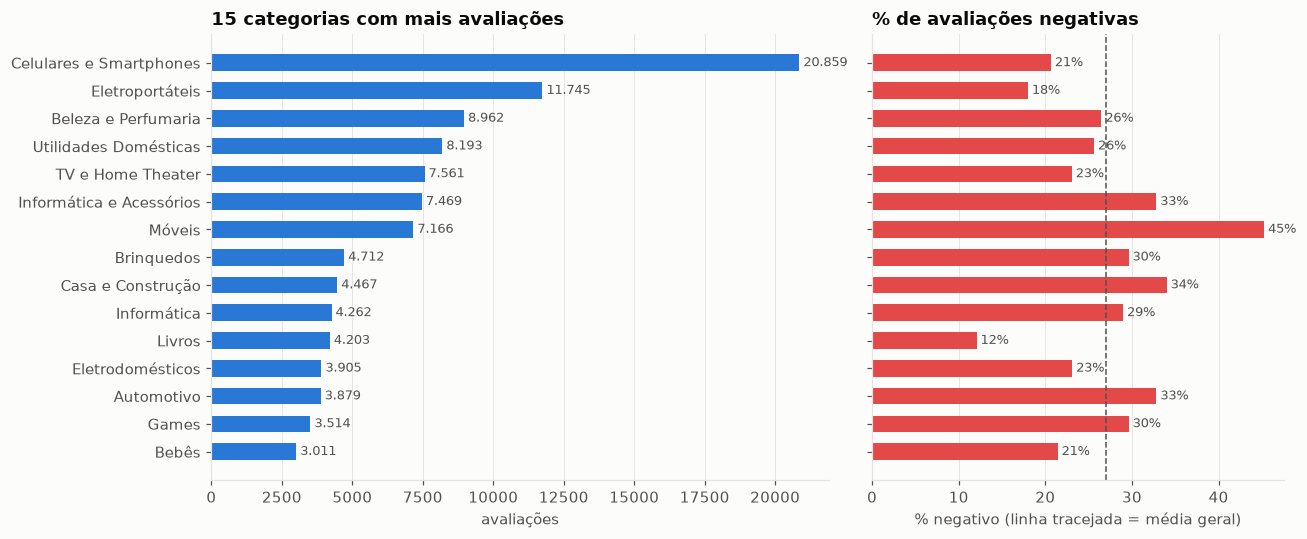

Categorias distintas (nível 1): 54


In [10]:
top_cat = df["site_category_lv1"].value_counts().head(15).sort_values()
neg_share = df[df.site_category_lv1.isin(top_cat.index)].groupby("site_category_lv1")["label"].apply(
    lambda s: 100 * (s == "negativo").mean()).reindex(top_cat.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
axes[0].barh(top_cat.index, top_cat.values, color=BLUE, height=0.6)
for y, v in enumerate(top_cat.values):
    axes[0].text(v, y, " " + fmt_int(v), va="center", fontsize=8.5, color=INK_2)
axes[0].set_title("15 categorias com mais avaliações")
axes[0].set_xlabel("avaliações"); axes[0].grid(axis="y", visible=False)
axes[1].barh(neg_share.index, neg_share.values, color=CLASS_COLORS["negativo"], height=0.6)
for y, v in enumerate(neg_share.values):
    axes[1].text(v, y, f" {v:.0f}%", va="center", fontsize=8.5, color=INK_2)
axes[1].axvline(100 * (df.label == "negativo").mean(), color=INK_2, lw=1, ls="--")
axes[1].set_title("% de avaliações negativas")
axes[1].set_xlabel("% negativo (linha tracejada = média geral)"); axes[1].grid(axis="y", visible=False)
fig.tight_layout()
savefig(fig, "04_categorias")
plt.show()
print(f"Categorias distintas (nível 1): {df.site_category_lv1.nunique()}")

O corpus é dominado por **celulares**, seguidos de eletroportáteis, beleza e utilidades domésticas.
A proporção de avaliações negativas varia muito entre categorias: cerca de 12% em **Livros** e 44% em
**Móveis**. Uma explicação plausível (não verificada aqui) é a logística: produtos grandes e frágeis
atrasam e chegam avariados com mais frequência, enquanto livros raramente dão problema. A categoria
**não** entra como variável no modelo, porque a tarefa é inferir o sentimento a partir do texto. Ainda
assim, ela é útil depois para analisar os erros por categoria.

### 2.6 Problemas de qualidade dos dados

In [11]:
title_norm = df["review_title"].map(normalize_text)
text_norm = df["review_text"].map(normalize_text)
inputs = pd.Series([build_input(a, b) for a, b in zip(title_norm, text_norm)], index=df.index)
n_words = inputs.map(count_words)

raw_text = df["review_text"].fillna("")
quality = pd.DataFrame.from_dict({
    "review_text nulo": df["review_text"].isna().sum(),
    "review_title nulo": df["review_title"].isna().sum(),
    "recommend_to_a_friend nulo": df["recommend_to_a_friend"].isna().sum(),
    "texto vazio/só espaços (não nulo)": ((text_norm == "") & df["review_text"].notna()).sum(),
    "linhas duplicadas (todas as colunas)": df.duplicated().sum(),
    "mesmo título+texto (duplicado de conteúdo)": inputs[df.review_text.notna()].duplicated().sum(),
    "  ...dos quais com rótulos diferentes": (
        pd.DataFrame({"i": inputs, "l": df.label})[df.review_text.notna()]
        .groupby("i")["l"].nunique().gt(1).sum()),
    "título+texto com < 10 palavras": (n_words < 10).sum(),
    "encoding quebrado (mojibake)": (df["review_title"].map(has_mojibake) | raw_text.map(has_mojibake)).sum(),
    "caracteres invisíveis/de controle": raw_text.str.contains(r"[​-‏﻿\x00-\x08]", regex=True).sum(),
    "quebras de linha no texto": raw_text.str.contains(r"[\r\n]", regex=True).sum(),
}, orient="index", columns=["ocorrências"])
display(quality)

,ocorrências
review_text nulo,3275
review_title nulo,302
recommend_to_a_friend nulo,18
texto vazio/só espaços (não nulo),0
linhas duplicadas (todas as colunas),955
mesmo título+texto (duplicado de conteúdo),2013
...dos quais com rótulos diferentes,5
título+texto com < 10 palavras,9078
encoding quebrado (mojibake),0
caracteres invisíveis/de controle,16


- **Nulos, vazios e duplicados** são tratados no funil da seção 3.
- **Duplicados de conteúdo** (mesmo título e texto, mas em outra linha, por exemplo a mesma avaliação
  publicada em duas versões do produto) são mais comuns que duplicados exatos. Se ficassem, a mesma
  frase poderia cair no treino e no teste, inflando a métrica (**vazamento**). Mantemos uma cópia
  quando o rótulo é igual e removemos o grupo inteiro quando os rótulos divergem.
- **Encoding quebrado:** não encontramos mojibake (`Ã©` no lugar de `é` etc.). O arquivo é UTF-8 limpo.
  O detector ignora de propósito palavras legítimas em maiúsculas, como "NÃO" e "IMÃ". A correção
  (`fix_encoding`) fica no pipeline mesmo assim, por segurança.
- Há alguns **caracteres invisíveis** (BOM, *zero-width space*), removidos na normalização.

### 2.7 Tamanho dos textos: palavras e tokens do BERTimbau

O BERT tem limite de 512 tokens, e o custo de treino cresce com o comprimento da sequência. Precisamos
de um `max_length` que cubra quase todos os textos sem desperdiçar memória com *padding*. Medimos
primeiro em **palavras** e depois em **tokens do próprio tokenizer do BERTimbau** (WordPiece). O número de
tokens é sempre maior que o de palavras: palavras raras, erros de digitação e pontuação viram vários
*subtokens*.

In [12]:
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # silencia o aviso de sequências > 512 tokens (não truncamos aqui)
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

valid = df["review_text"].notna()
eda_len = pd.DataFrame({
    "label": df.loc[valid, "label"],
    "palavras_titulo": title_norm[valid].map(count_words),
    "palavras_texto": text_norm[valid].map(count_words),
    "palavras_entrada": n_words[valid],
})
enc = tokenizer(inputs[valid].tolist(), add_special_tokens=True, truncation=False)
eda_len["tokens_entrada"] = [len(ids) for ids in enc["input_ids"]]

pcts = [0.5, 0.75, 0.9, 0.95, 0.98, 0.99]
display(eda_len.drop(columns="label").describe(percentiles=pcts).T.round(1))
print(f"Razão média tokens/palavras: {(eda_len.tokens_entrada / eda_len.palavras_entrada.clip(lower=1)).mean():.2f}")

,count,mean,std,min,50%,75%,90%,95%,98%,99%,max
palavras_titulo,129098.0,3.0,2.4,0.0,2.0,4.0,6.0,8.0,10.0,13.0,30.0
palavras_texto,129098.0,23.0,22.2,1.0,16.0,27.0,45.0,62.0,88.0,112.0,795.0
palavras_entrada,129098.0,26.1,22.7,2.0,19.0,30.0,49.0,66.0,93.0,116.0,802.0
tokens_entrada,129098.0,43.5,39.2,5.0,32.0,49.0,78.0,105.0,148.0,189.0,2373.0


Razão média tokens/palavras: 1.94


figura salva em reports/figures/05_tamanho_palavras_tokens.png


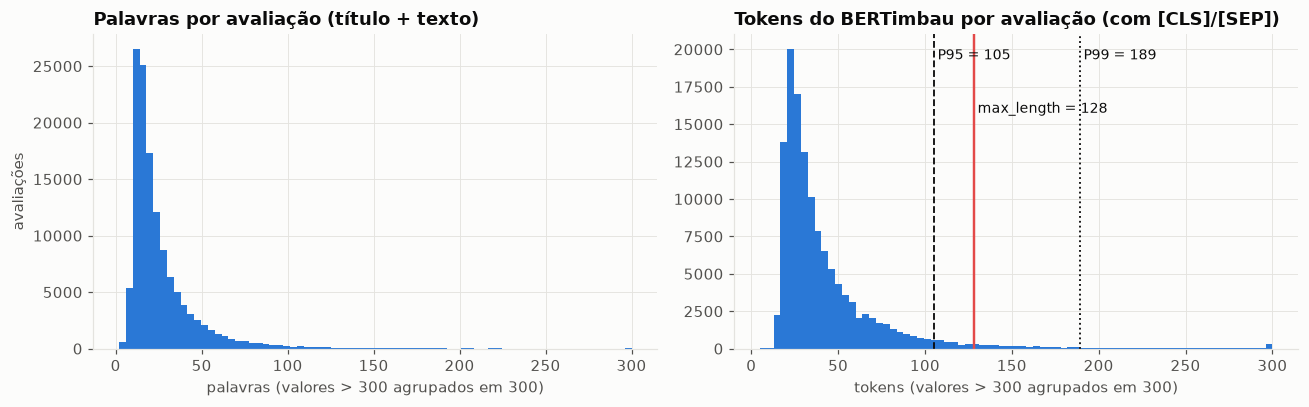

,% textos sem truncamento
max_length,
32,51.34
64,85.03
96,93.95
128,97.03
192,99.04
256,99.56
512,99.96


In [13]:
p95, p99 = eda_len["tokens_entrada"].quantile([0.95, 0.99])
clip = 300  # só para o gráfico; a cauda longa vai até centenas de tokens

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.hist(eda_len["palavras_entrada"].clip(upper=clip), bins=75, color=BLUE)
ax.set_title("Palavras por avaliação (título + texto)")
ax.set_xlabel(f"palavras (valores > {clip} agrupados em {clip})"); ax.set_ylabel("avaliações")

ax = axes[1]
ax.hist(eda_len["tokens_entrada"].clip(upper=clip), bins=75, color=BLUE)
for q, v, ls in [("P95", p95, "--"), ("P99", p99, ":")]:
    ax.axvline(v, color=INK, lw=1.2, ls=ls)
    ax.text(v, ax.get_ylim()[1] * 0.92, f" {q} = {v:.0f}", fontsize=9, color=INK)
ax.axvline(128, color=CLASS_COLORS["negativo"], lw=1.6)
ax.text(128, ax.get_ylim()[1] * 0.75, " max_length = 128", fontsize=9, color=INK)
ax.set_title("Tokens do BERTimbau por avaliação (com [CLS]/[SEP])")
ax.set_xlabel(f"tokens (valores > {clip} agrupados em {clip})")
fig.tight_layout()
savefig(fig, "05_tamanho_palavras_tokens")
plt.show()

coverage = pd.DataFrame({
    "max_length": [32, 64, 96, 128, 192, 256, 512],
})
coverage["% textos sem truncamento"] = coverage["max_length"].map(lambda m: round(100 * (eda_len.tokens_entrada <= m).mean(), 2))
display(coverage.set_index("max_length"))

figura salva em reports/figures/06_tokens_por_classe.png


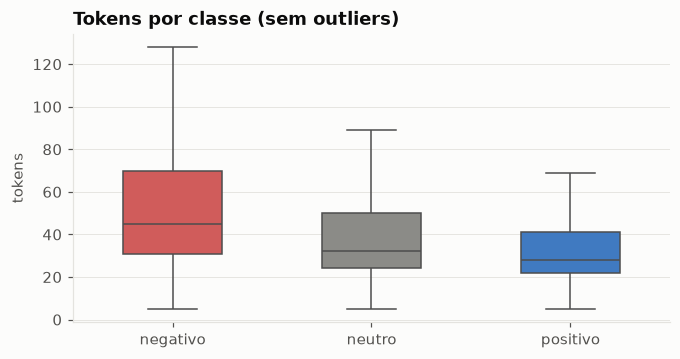

,mediana palavras_titulo,mediana palavras_texto,mediana tokens_entrada
label,,,
negativo,3.0,24.0,45.0
neutro,2.0,17.0,32.0
positivo,2.0,14.0,28.0


In [14]:
fig, ax = plt.subplots(figsize=(7, 3.4))
order = SENTIMENT_LABELS
sns.boxplot(data=eda_len, x="label", y="tokens_entrada", order=order, hue="label", hue_order=order,
            palette=CLASS_COLORS, showfliers=False, width=0.5, linewidth=1, ax=ax, legend=False)
ax.set_title("Tokens por classe (sem outliers)")
ax.set_xlabel(""); ax.set_ylabel("tokens")
ax.grid(axis="x", visible=False)
savefig(fig, "06_tokens_por_classe")
plt.show()
display(eda_len.groupby("label")[["palavras_titulo", "palavras_texto", "tokens_entrada"]].median()
        .rename(columns=lambda c: f"mediana {c}"))

**Escolha do `max_length`:**

- As avaliações são curtas: a mediana é de cerca de 32 tokens (19 palavras), e o **percentil 95 (P95)
  fica em torno de 105 tokens**. Cada palavra vira, em média, cerca de 2 tokens.
- Escolhemos **`max_length = 128`**: fica logo acima do P95, cobre cerca de 97% das avaliações sem
  nenhum truncamento e é múltiplo de 8, o que é eficiente em GPU.
- Ir para 256 cobriria cerca de 99,5% e **dobraria o custo** de atenção e memória de cada lote por um
  ganho marginal. Nos textos que passam de 128 tokens, o começo (título e primeiras frases) costuma já
  trazer a opinião.
- O valor é confirmado no **conjunto de treino** na seção 8, para que nenhuma escolha dependa da
  validação ou do teste.

**Por classe:** avaliações **negativas** são bem mais longas (quem está insatisfeito explica o
problema), enquanto as positivas são curtas ("Ótimo produto, recomendo"). O tamanho em si já carrega
sinal. Isso também ajuda a explicar por que o filtro de "menos de 10 palavras" (seção 3) remove
principalmente exemplos positivos.

### 2.8 Palavras mais frequentes por classe (sem stopwords)

Usamos a versão do texto preparada para o baseline (minúsculas, sem pontuação, sem stopwords).
**Importante:** palavras de negação, contraste e intensidade (`não`, `nem`, `nunca`, `sem`, `mas`,
`muito`...) foram **retiradas da lista de stopwords**. Numa tarefa de sentimento, "não recomendo" e
"recomendo" precisam continuar diferentes.

figura salva em reports/figures/07_palavras_por_classe.png


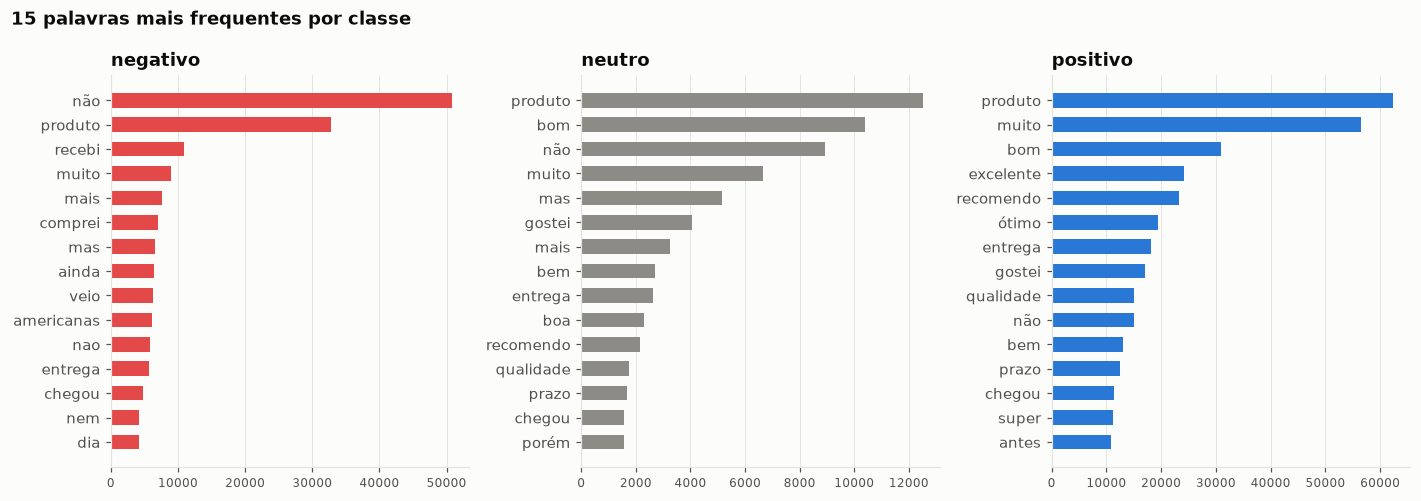

In [15]:
from collections import Counter

tfidf_preview = inputs[valid].map(text_for_tfidf)
top_words = {}
for lab in SENTIMENT_LABELS:
    c = Counter(w for t in tfidf_preview[df.loc[valid, "label"] == lab] for w in t.split())
    top_words[lab] = pd.Series(dict(c.most_common(15)))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, lab in zip(axes, SENTIMENT_LABELS):
    s = top_words[lab].sort_values()
    ax.barh(s.index, s.values, color=CLASS_COLORS[lab], height=0.6)
    ax.set_title(lab)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("15 palavras mais frequentes por classe", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "07_palavras_por_classe")
plt.show()

"produto", "muito" e "não" estão entre as mais frequentes em **todas** as classes. Contagem bruta
mistura vocabulário comum e vocabulário discriminativo, mas o padrão é claro:

- **negativo:** `não` lidera com folga, seguido de `recebi`, `comprei`, `ainda`, `veio`, `americanas`,
  `entrega`, `chegou`, `nem`, `dia`. **Grande parte das queixas é sobre a entrega e a loja**, e não
  sobre o produto em si;
- **neutro:** mistura de elogio e ressalva: `bom`, `gostei` e `recomendo` ao lado de `mas` e `porém`.
  As conjunções de contraste são uma marca típica da classe;
- **positivo:** `bom`, `excelente`, `recomendo`, `ótimo`, `gostei`, `qualidade`, `super`, `antes` (do
  prazo).

Dois detalhes reforçam decisões do pré-processamento: (1) `não`, `mas` e `porém` estão no topo, o que
justifica **não** tratá-las como stopwords; (2) `nao`, sem acento, aparece ao lado de `não`. Erros de
digitação e falta de acentos são comuns, o que pesa contra modelos de vocabulário fechado e a favor
da tokenização em *subwords* do BERT.

O neutro compartilha vocabulário com as duas outras classes, o que confirma que será a classe mais
difícil.

**Exemplos de avaliações por classe** (amostra aleatória, texto já mascarado):

In [16]:
examples = pd.DataFrame({"label": df.loc[valid, "label"], "nota": df.loc[valid, "overall_rating"], "entrada": inputs[valid]})
for lab in SENTIMENT_LABELS:
    print(f"\n=== {lab.upper()} ===")
    for _, r in examples[examples.label == lab].sample(4, random_state=SEED).iterrows():
        print(f"  ({r.nota}★) {r.entrada[:260]}")


=== NEGATIVO ===
  (1★) Péssimo. O produto veio com defeito e a paizão store não esta querendo me devolver o dinheiro. muito chateado.
  (1★) J7 PRIME PAROU DE FUNCIONAE COM MENOS DE 4 MESES DE USO. ELE CHEGOU DIA 24/09/2017 O utilizei normalmente antes de dormir. O coloquei ao lado da cama, por volta das 23:30 de ontem dia 17/01/2018 e hoje 18/01/2017 as. 2:30 ele simplesmente nao liga. Sempre usei
  (2★) Não é tão bom. Não ativa a função ‘descer e subir ‘, não sei se veio com defeito mas não estou satisfeita..
  (1★) Poltrona com defeito. Produto chegou mofado e com o revestimento (mapa)podre Estou aguardando a coletável posteriormente o reembolso.

=== NEUTRO ===
  (3★) Produto bom, entrega imcompleta. O Produto está dentro das expectativas, mas a vendedora não encaminhou junto a bolsa que deria acompanhar o produto. Acionada por um dos canais de comunicação disponibilizados, limitou-se a indicar outro canal, transferindo o ô
  (3★) bom mas... após carregar o aparelho por 10 horas 

## 3. Limpeza: funil

Etapas aplicadas, em ordem (cada uma é registrada no funil):

1. **Nulos:** remove linhas sem `review_text` ou sem `recommend_to_a_friend`.
2. **Textos vazios:** remove textos que ficam vazios após a normalização.
3. **Duplicados exatos:** remove linhas idênticas em todas as colunas.
4. **Duplicados de conteúdo:** mesmo título + texto. Mantém a primeira ocorrência se o rótulo for o
   mesmo e remove o grupo inteiro se os rótulos divergirem.
5. **Textos curtos:** remove entradas (título + texto) com **menos de 10 palavras**.

Rótulos contraditórios **não** são removidos (decisão justificada na seção 2.4).

**Sobre o corte de 10 palavras.** Avaliações de produto são naturalmente curtas: só o `review_text`
tem mediana de 16 palavras, e aplicar o corte a ele removeria cerca de 17% da base. Por isso o corte é
aplicado à **entrada do modelo (título + texto)**. Assim ele remove só os textos realmente sem
conteúdo ("Ótimo. Recomendo", "Bom. ok") e preserva avaliações curtas, mas informativas. Como mostrado
na EDA, quase tudo o que sai é **positivo**, a classe majoritária, então o corte não prejudica as
classes minoritárias.

In [17]:
MIN_WORDS = 10

base = df.copy()
base["review_title"] = title_norm.fillna("")
base["review_text"] = text_norm
base["texto"] = inputs
base["n_palavras"] = n_words

funnel = CleaningFunnel(base)
funnel.step("1. nulos (review_text ou recommend_to_a_friend)",
            df["review_text"].notna() & df["recommend_to_a_friend"].notna())
funnel.step("2. texto vazio após normalização", funnel.df["review_text"].str.len() > 0)
funnel.step("3. duplicados exatos", ~funnel.df.drop(columns=["texto", "n_palavras"]).duplicated())
funnel.step("4. duplicados de conteúdo (título+texto)", mask_conflicting_duplicates(funnel.df, "texto", "label"))
funnel.step(f"5. entrada com < {MIN_WORDS} palavras", funnel.df["n_palavras"] >= MIN_WORDS)

clean = funnel.df.reset_index(drop=True)
funnel_report = funnel.report()
display(funnel_report)
print(f"Total removido: {fmt_int(len(df) - len(clean))} linhas ({100 * (1 - len(clean) / len(df)):.1f}%). Restam {fmt_int(len(clean))}.")

,etapa,removidas,restantes,% da base original
0,Base original,0,132373,0.00
1,1. nulos (review_text ou recommend_to_a_friend),3293,129080,2.49
2,2. texto vazio após normalização,0,129080,0.00
3,3. duplicados exatos,872,128208,0.66
4,4. duplicados de conteúdo (título+texto),1131,127077,0.85
5,5. entrada com < 10 palavras,5939,121138,4.49


Total removido: 11.235 linhas (8.5%). Restam 121.138.


In [18]:
dist_before = df["label"].value_counts(normalize=True).mul(100).round(1)
dist_after = clean["label"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"% antes da limpeza": dist_before, "% depois da limpeza": dist_after}).reindex(SENTIMENT_LABELS))

,% antes da limpeza,% depois da limpeza
label,,
negativo,27.0,26.8
neutro,12.3,12.6
positivo,60.7,60.6


A limpeza remove cerca de 8,5% das linhas, e a maior parte vem do filtro de tamanho e dos nulos. A
distribuição das classes **praticamente não muda** (variações abaixo de 1 ponto percentual), então a
limpeza não cria nem corrige desbalanceamento.

## 4. Normalização do texto e encoding dos rótulos

### 4.1 Texto para o BERTimbau (coluna `texto`)

`normalize_text` (em `src/clean.py`) faz:

1. **corrige encoding** (desfaz mojibake simples, por exemplo `Ã©` → `é`);
2. normaliza o **Unicode para NFC** (o mesmo caractere acentuado sempre com a mesma sequência de
   bytes; `e` + acento combinante vira `é`);
3. remove **caracteres invisíveis** (BOM, *zero-width space*, caracteres de controle);
4. colapsa **espaços, tabulações e quebras de linha** em um único espaço.

**O que propositalmente NÃO fazemos:** converter para minúsculas, remover acentos ou remover
pontuação. O modelo `bert-base-portuguese-cased` é **cased**: o vocabulário distingue "Ótimo",
"ótimo" e "ÓTIMO" e foi pré-treinado com acentos. Mexer nisso faria o texto se afastar do que o modelo
viu no pré-treino e geraria mais *subtokens* desconhecidos. Letras maiúsculas ("PÉSSIMO!!!") e
pontuação repetida também carregam intensidade de sentimento.

A entrada final do modelo é **`"<título>. <texto>"`**. O título funciona como um resumo da opinião
("Não recomendo", "Excelente"). Na seção 6.2 verificamos empiricamente se ele ajuda.

In [19]:
changed = df["review_text"].notna() & (df["review_text"].fillna("") != text_norm)
print(f"Textos alterados pela normalização: {changed.sum()} de {df['review_text'].notna().sum()}")
demo = pd.DataFrame({"antes": df.loc[changed, "review_text"].map(repr), "depois": text_norm[changed].map(repr)})
display(demo[demo["antes"].str.contains(r"\\u|\\x|  ", regex=True)].head(4))

Textos alterados pela normalização: 20511 de 129098


,antes,depois
2,"'SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANELAS ELÉTRICAS. COSTUMO USAR OUTRA PANELA PARA COZIMENTO DE ARROZ (JAPONESA), MAS LEVA MUITO TEMPO, +/- 50 MINUTOS. NESSA PANELA É MUITO MAIS RÁPID...","'SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANELAS ELÉTRICAS. COSTUMO USAR OUTRA PANELA PARA COZIMENTO DE ARROZ (JAPONESA), MAS LEVA MUITO TEMPO, +/- 50 MINUTOS. NESSA PANELA É MUITO MAIS RÁPIDO, E..."
21,"'Pontos Positivos Painel de 10bits (isso faz toda diferença da mais de 1 bilhão de cores) Bluetooth Wi-Fi AC USB 3.0 Input Lag Baixo Painel VA, que proporciona um alto contraste. Android TV 6.0 So...","'Pontos Positivos Painel de 10bits (isso faz toda diferença da mais de 1 bilhão de cores) Bluetooth Wi-Fi AC USB 3.0 Input Lag Baixo Painel VA, que proporciona um alto contraste. Android TV 6.0 So..."
31,'Não recebi segundo o correio o endereço estava errado! Porém o outro pedido recebi!','Não recebi segundo o correio o endereço estava errado! Porém o outro pedido recebi!'
37,'Melhor custo benefício. Exatamente como anunciado. Recomendo .','Melhor custo benefício. Exatamente como anunciado. Recomendo .'


### 4.2 Texto para o baseline TF-IDF (coluna `texto_tfidf`)

Para o baseline clássico, o pré-processamento é outro. Numa representação de saco de palavras, "Ótimo"
e "ótimo" devem contar como a mesma palavra, e stopwords só aumentam a dimensionalidade. A coluna
separada `texto_tfidf` tem **minúsculas, só palavras (sem números ou pontuação) e sem stopwords**,
mantendo as negações. Assim o BERTimbau recebe o texto original normalizado, e o baseline recebe a
versão adequada a ele.

In [20]:
clean["texto_tfidf"] = clean["texto"].map(text_for_tfidf)
display(clean[["texto", "texto_tfidf"]].sample(3, random_state=SEED))

,texto,texto_tfidf
111938,"S/ palavras. Não tenho muito a descrever, mas vai ser muito útil p/ qm utilizar. :-)",palavras não muito descrever mas vai muito útil qm utilizar
15720,Muito bom. pratico e perfeito para as necessidades do mesmo. estou satisfeito com produto e recomendo.,muito bom pratico perfeito necessidades satisfeito produto recomendo
18145,"Presente. Foi um presente para uma criança,pois a mesma ficou muito feliz com o produto.",presente presente criança pois mesma ficou muito feliz produto


### 4.3 Encoding dos rótulos

`LabelEncoder` transforma as classes em inteiros (ordem alfabética: negativo = 0, neutro = 1,
positivo = 2, que coincide com a ordem natural da polaridade). O mapeamento classe ↔ id é salvo em
JSON para ser reutilizado no treinamento e na inferência. O encoder é ajustado sobre a **lista fixa das
3 classes**, não sobre os dados, então não há risco de vazamento nem de mudar a numeração.

In [21]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(SENTIMENT_LABELS)
clean["label_id"] = le.transform(clean["label"])
label_mapping = {
    "label2id": {c: int(i) for c, i in zip(le.classes_, le.transform(le.classes_))},
    "id2label": {int(i): c for c, i in zip(le.classes_, le.transform(le.classes_))},
    "regra": "overall_rating 1-2 -> negativo, 3 -> neutro, 4-5 -> positivo",
}
save_json(label_mapping, PROC_DIR / "label_mapping.json")
print(json.dumps(label_mapping, ensure_ascii=False, indent=2))

{
  "label2id": {
    "negativo": 0,
    "neutro": 1,
    "positivo": 2
  },
  "id2label": {
    "0": "negativo",
    "1": "neutro",
    "2": "positivo"
  },
  "regra": "overall_rating 1-2 -> negativo, 3 -> neutro, 4-5 -> positivo"
}


## 5. Divisão temporal em treino / validação / teste

**Por que temporal, e não aleatória?** Em produção, o modelo é treinado com avaliações do passado e
usado em avaliações **futuras**. Uma divisão aleatória misturaria dias: o modelo veria no treino
avaliações escritas no mesmo dia, sobre os mesmos produtos e promoções, que as do teste, e o resultado
seria otimista (vazamento temporal). Com a divisão temporal:

- **treino** = 70% mais antigos, **validação** = 15% seguintes, **teste** = 15% mais recentes;
- o teste simula "o modelo encontrando o mês seguinte", incluindo eventual *drift* de produtos,
  campanhas e vocabulário.

**O período (5 meses) é curto demais?** Não. Os cortes são feitos por **posição na ordem cronológica**
(e não por mês inteiro), então as proporções ficam exatamente em 70/15/15 apesar do mês de fevereiro
mais fraco. Cada conjunto tem milhares de exemplos de cada classe, como mostra a tabela abaixo. Por
isso mantemos a divisão temporal. A alternativa estratificada aleatória (`stratified_split`) fica
disponível em `src/split.py`, mas não é usada.

In [22]:
train, val, test = temporal_split(clean, "submission_date", train_frac=0.70, val_frac=0.15)
parts = {"treino": train, "validação": val, "teste": test}
summary = split_summary(parts, "label", "submission_date")
display(summary)
display(pd.DataFrame({k: p["label"].value_counts() for k, p in parts.items()}).reindex(SENTIMENT_LABELS)
        .rename_axis("contagem por classe"))
assert len(train) + len(val) + len(test) == len(clean)
assert train.submission_date.max() <= val.submission_date.min() <= val.submission_date.max() <= test.submission_date.min()

,linhas,% do total,início,fim,% negativo,% neutro,% positivo
conjunto,,,,,,,
treino,84797,70.0,2018-01-01 00:11:28,2018-04-16 16:03:30,26.3,12.6,61.2
validação,18170,15.0,2018-04-16 16:03:44,2018-05-07 08:02:58,26.8,12.7,60.5
teste,18171,15.0,2018-05-07 08:03:02,2018-05-31 23:50:33,29.1,12.8,58.1


,treino,validação,teste
contagem por classe,,,
negativo,22262,4870,5281
neutro,10649,2305,2325
positivo,51886,10995,10565


figura salva em reports/figures/08_classes_por_conjunto.png


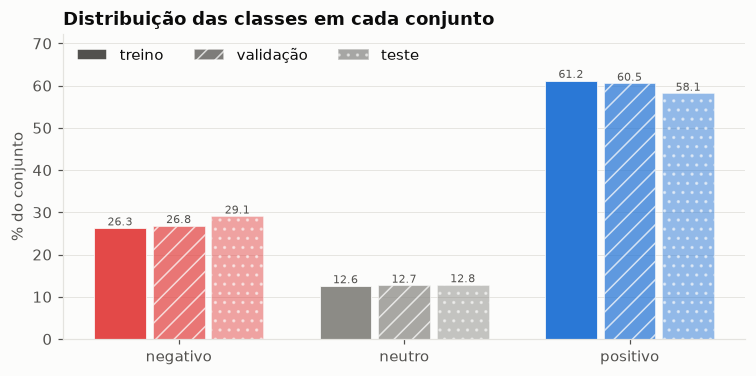

In [23]:
dist = pd.DataFrame({k: p["label"].value_counts(normalize=True).mul(100) for k, p in parts.items()}).reindex(SENTIMENT_LABELS)

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(SENTIMENT_LABELS))
width = 0.26
hatches = {"treino": "", "validação": "//", "teste": ".."}
for i, (name, col) in enumerate(dist.items()):
    bars = ax.bar(x + (i - 1) * width, col.values, width=width - 0.03,
                  color=[CLASS_COLORS[c] for c in SENTIMENT_LABELS], alpha=[1, 0.75, 0.5][i],
                  hatch=hatches[name], edgecolor=SURFACE, linewidth=0.5, label=name)
    for xi, v in zip(x + (i - 1) * width, col.values):
        ax.text(xi, v, f"{v:.1f}", ha="center", va="bottom", fontsize=7.5, color=INK_2)
ax.set_xticks(x, SENTIMENT_LABELS)
ax.set_ylabel("% do conjunto")
ax.set_title("Distribuição das classes em cada conjunto")
# Legenda com amostras neutras: a cor indica a classe (eixo x); a textura/opacidade indica o conjunto
from matplotlib.patches import Patch
handles = [Patch(facecolor=INK_2, alpha=a, hatch=hatches[n], edgecolor=SURFACE, label=n)
           for n, a in zip(dist.columns, [1, 0.75, 0.5])]
ax.legend(handles=handles, ncols=3, loc="upper left")
ax.set_ylim(0, dist.values.max() * 1.18)
ax.grid(axis="x", visible=False)
savefig(fig, "08_classes_por_conjunto")
plt.show()

**Comentário:** as proporções mudam um pouco ao longo do tempo. A tabela mostra quanto o percentual
de negativos varia entre treino, validação e teste. Isso é esperado num corte temporal (sazonalidade,
campanhas e problemas logísticos pontuais mudam o mix de avaliações) e é justamente o tipo de mudança
que o modelo enfrentaria em produção. Por isso a métrica principal é o **F1-macro**, menos sensível à
proporção entre as classes que a acurácia. A diferença é pequena e as três classes estão bem
representadas em todos os conjuntos.

Uma checagem extra de vazamento: como os duplicados de conteúdo foram removidos antes da divisão,
**nenhum texto de entrada aparece em mais de um conjunto**:

In [24]:
overlap_tv = len(set(train.texto) & set(val.texto))
overlap_tt = len(set(train.texto) & set(test.texto))
print(f"Textos idênticos treino∩validação: {overlap_tv} | treino∩teste: {overlap_tt}")

Textos idênticos treino∩validação: 0 | treino∩teste: 0


## 6. Ajustes feitos SÓ no treino

Regra geral para evitar vazamento: **tudo o que "aprende" algo dos dados (`fit`) é ajustado apenas no
treino** e depois só aplicado (`transform`) na validação e no teste. Neste pré-processamento isso vale
para:

| Item | Ajustado em | Aplicado em |
|---|---|---|
| Vocabulário e IDF do TF-IDF | treino | validação, teste |
| Pesos de classe | treino | função de perda no treinamento |
| Data augmentation (se aplicado) | treino | só treino (nunca validação ou teste) |
| `max_length` | distribuição do treino | todos |

Regras fixas, que não aprendem dos dados (normalização, mascaramento, mapeamento da nota para a classe,
`LabelEncoder` sobre a lista fixa de classes), podem ser aplicadas a tudo antes da divisão.

### 6.1 Pesos de classe

Com o desbalanceamento observado, usamos pesos inversamente proporcionais à frequência de cada classe
**no treino** (`class_weight="balanced"` do scikit-learn: `n / (k · n_c)`). Na próxima etapa eles
entram na `CrossEntropyLoss` do BERTimbau: errar um neutro custa mais que errar um positivo.

In [25]:
class_weights = class_weights_from_train(train["label_id"].to_numpy(), np.arange(len(le.classes_)))
cw_named = {le.classes_[i]: w for i, w in class_weights.items()}
save_json({"por_id": class_weights, "por_classe": cw_named, "calculado_em": "treino", "n_treino": len(train)},
          PROC_DIR / "class_weights.json")
display(pd.DataFrame({"frequência no treino": train["label"].value_counts(), "peso": pd.Series(cw_named)}).reindex(SENTIMENT_LABELS))

,frequência no treino,peso
negativo,22262,1.2697
neutro,10649,2.6543
positivo,51886,0.5448


### 6.2 O título ajuda?

Para decidir com dados se a entrada deve ser só `review_text` ou `título + texto`, treinamos o
**baseline** (TF-IDF + regressão logística) nas duas versões e comparamos o **F1-macro na validação**.
O TF-IDF é ajustado (`fit`) **só no treino**; a validação passa apenas pelo `transform`. O conjunto de
teste não é tocado aqui.

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score


def run_baseline(train_text, y_train, val_text, y_val, class_weight="balanced"):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000, sublinear_tf=True)
    X_train = vec.fit_transform(train_text)   # fit SÓ no treino
    X_val = vec.transform(val_text)           # validação: apenas transform
    clf = LogisticRegression(max_iter=2000, C=2.0, class_weight=class_weight, random_state=SEED)
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)
    return f1_score(y_val, pred, average="macro"), pred


y_tr, y_va = train["label_id"], val["label_id"]
f1_text, _ = run_baseline(train["review_text"].map(text_for_tfidf), y_tr, val["review_text"].map(text_for_tfidf), y_va)
f1_full, pred_full = run_baseline(train["texto_tfidf"], y_tr, val["texto_tfidf"], y_va)
title_cmp = pd.DataFrame({"entrada": ["só review_text", "título + texto"], "F1-macro (validação)": [f1_text, f1_full]})
display(title_cmp.round(4))
print(classification_report(y_va, pred_full, target_names=le.classes_, digits=3))

,entrada,F1-macro (validação)
0,só review_text,0.7086
1,título + texto,0.7599


              precision    recall  f1-score   support

    negativo      0.867     0.907     0.886      4870
      neutro      0.435     0.588     0.500      2305
    positivo      0.940     0.851     0.893     10995

    accuracy                          0.833     18170
   macro avg      0.747     0.782     0.760     18170
weighted avg      0.856     0.833     0.841     18170



**Conclusão:** incluir o título **melhora o F1-macro na validação em cerca de 5 pontos** (veja a
tabela), um ganho grande para uma mudança tão simples. O título costuma resumir a opinião em poucas
palavras ("Não recomendo", "Excelente", "Bom, mas..."), justamente o que mais ajuda a separar as
classes. O custo é pequeno: a mediana do título é de 2 a 3 palavras. Mantemos **`título + texto`**
como entrada para o baseline e para o BERTimbau.

O relatório por classe confirma a expectativa da EDA: negativo e positivo ficam perto de 0,89 de F1,
enquanto o **neutro fica em torno de 0,50**. É nele que está a margem de melhora para o BERTimbau.

Os números desta tabela são uma **primeira referência do baseline** (TF-IDF + regressão logística com
pesos de classe). A avaliação formal, no teste, fica para a próxima etapa, junto com o BERTimbau.

## 7. Data augmentation: vale a pena?

**Argumentos contra, específicos deste problema:**

1. **Volume já suficiente.** O treino tem dezenas de milhares de exemplos, e a menor classe (neutro)
   tem cerca de 10 mil. *Augmentation* de texto costuma ajudar quando há centenas ou poucos milhares
   de exemplos; com esse volume, o ganho reportado na literatura (inclusive no artigo original do EDA,
   de Wei & Zou, 2019) tende a zero.
2. **Risco de trocar o rótulo.** Em sentimento, a remoção aleatória pode apagar justamente a palavra
   que define a classe: "não recomendo" vira "recomendo". A troca de posição pode separar a negação do
   verbo. Ou seja, o *augmentation* pode **injetar ruído de rótulo** na classe mais delicada.
3. **Modelos pré-treinados** como o BERTimbau já têm conhecimento linguístico robusto. Variações
   artificiais e agramaticais ("chegou produto o rápido") se afastam da distribuição real dos textos.
4. O desbalanceamento já é tratado pelos **pesos de classe** (seção 6.1), sem criar dados artificiais.

**Experimento** para não decidir só por argumento: aplicamos EDA (troca e remoção aleatória de
palavras, `alpha = 0.1`) **somente no treino e somente na classe minoritária (neutro)**, dobrando-a, e
comparamos o baseline na validação. É um *proxy* (o efeito no BERT pode ser diferente), mas indica a
tendência.

In [27]:
aug_train = augment_minority(train, "texto", "label", classes=["neutro"], factor=1, alpha=0.1, seed=SEED)
aug_train["texto_tfidf"] = aug_train["texto"].map(text_for_tfidf)

print("Exemplos antes → depois (neutro):")
neutral_examples = train[train.label == "neutro"].sample(3, random_state=SEED)["texto"]
for t in neutral_examples:
    print(f"  ANTES : {t[:200]}")
    print(f"  DEPOIS: {eda_augment(t, alpha=0.1, seed=7)[:200]}\n")

dist_aug = pd.DataFrame({
    "treino original": train["label"].value_counts(),
    "treino com augmentation": aug_train["label"].value_counts(),
}).reindex(SENTIMENT_LABELS)
dist_aug["% original"] = (100 * dist_aug["treino original"] / dist_aug["treino original"].sum()).round(1)
dist_aug["% com augmentation"] = (100 * dist_aug["treino com augmentation"] / dist_aug["treino com augmentation"].sum()).round(1)
display(dist_aug)

Exemplos antes → depois (neutro):
  ANTES : Tapete. Pedido chegou antes do prazo estimado, material e acabamentos são bons, muito bonito, só uma coisa não agradou, não tem nada a ver com o anunciado, não é muito peludo
  DEPOIS: tem chegou muito estimado, acabamentos peludo bons, do bonito, só uma coisa não não Pedido nada a ver com o anunciado, não é muito

  ANTES : Gosto desse produto. Produto de boa qualidade so deveria manter mais a temperatura gelada
  DEPOIS: Gosto boa de produto. qualidade deveria manter mais temperatura gelada

  ANTES : demora na entrega. celular é bom mais pra entrega uma demora falaram 4 dias uteis mais na verdade é outra coisa cidade do lado da minha e demora mais de 1 dia pra entrega ta parado la mais de 24 horas
  DEPOIS: demora entrega. celular pra entrega coisa demora falaram 4 dias uteis mais verdade é outra uma cidade do lado da 10 e demora 1 dia pra entrega mais parado la mais de 24 horas minha km só a cidade vizi



,treino original,treino com augmentation,% original,% com augmentation
label,,,,
negativo,22262,22262,26.3,23.3
neutro,10649,21298,12.6,22.3
positivo,51886,51886,61.2,54.4


In [28]:
# Quantas vezes a remoção aleatória apagou uma negação (risco de inverter o sentido)?
import re

neg_re = re.compile(r"\b(?:não|nem|nunca)\b", re.IGNORECASE)
orig = train[train.label == "neutro"]["texto"].reset_index(drop=True)
augm = aug_train[aug_train.augmented]["texto"].reset_index(drop=True)
had_neg = orig.str.count(neg_re)
lost_neg = (had_neg > augm.str.count(neg_re))
print(f"Textos neutros com negação: {(had_neg > 0).sum()} | versões aumentadas que perderam ao menos uma negação: "
      f"{lost_neg.sum()} ({100 * lost_neg.sum() / max((had_neg > 0).sum(), 1):.1f}% dos que tinham)")
ex = lost_neg[lost_neg].index[:2]
for i in ex:
    print(f"\n  ANTES : {orig[i][:220]}\n  DEPOIS: {augm[i][:220]}")

Textos neutros com negação: 3890 | versões aumentadas que perderam ao menos uma negação: 572 (14.7% dos que tinham)

  ANTES : Podia ser melhor... O jogo está longe de conseguir se igualar aos antigos Tony Hawk. A jogabilidade e os desafios não são dos melhores, mas pelo preço que paguei até que vale umas horas de jogo. Nada a reclamar da entreg
  DEPOIS: Podia ser melhor... O jogo está longe de conseguir paguei A aos antigos Tony como jogabilidade e os reclamar melhores, mas pelo preço que se que vale umas horas de jogo. Nada a dos da entrega da Americanas, rápida e igua

  ANTES : Avaliação do produto. Minha avaliação foi considerada "bom" não pelo produto e sim pelo prazo de entrega que não foi cumprido, acredito que a empresa fornecedora deveria programar-se melhor quanto ao prazo de entrega par
  DEPOIS: do acredito Minha avaliação foi considerada não de produto e prazo pelo prazo. que pelo cumprido, fornecedora que empresa produto. deveria programar-se melhor minha ao prazo de en

In [29]:
# O augmentation é aleatório: repetimos com 3 sementes para separar efeito real de variação ao acaso.
# Também testamos "oversampling" (duplicar os neutros sem alterá-los), para isolar o efeito
# de ter MAIS neutros do efeito de ter neutros DIFERENTES.
oversampled = pd.concat([train, train[train.label == "neutro"]], ignore_index=True)

configs = [("sem pesos, sem augmentation", train, None, None),
           ("pesos de classe", train, "balanced", None),
           ("oversampling do neutro (cópias idênticas), sem pesos", oversampled, None, None)]
for s in (SEED, SEED + 1, SEED + 2):
    a = augment_minority(train, "texto", "label", classes=["neutro"], factor=1, alpha=0.1, seed=s)
    a["texto_tfidf"] = a["texto"].map(text_for_tfidf)
    configs.append(("augmentation EDA do neutro, sem pesos", a, None, s))
    configs.append(("augmentation EDA do neutro + pesos de classe", a, "balanced", s))

results = []
for name, tr, cw, s in configs:
    f1, _ = run_baseline(tr["texto_tfidf"], tr["label_id"], val["texto_tfidf"], y_va, class_weight=cw)
    results.append({"configuração (treino)": name, "semente": s, "linhas de treino": len(tr), "F1-macro": f1})
aug_results = (pd.DataFrame(results).groupby("configuração (treino)", sort=False)
               .agg(linhas_de_treino=("linhas de treino", "first"), execuções=("F1-macro", "size"),
                    f1_macro_validação=("F1-macro", "mean"), desvio_padrão=("F1-macro", "std"))
               .round(4))
display(aug_results)

,linhas_de_treino,execuções,f1_macro_validação,desvio_padrão
configuração (treino),,,,
"sem pesos, sem augmentation",84797,1,0.7467,NaN
pesos de classe,84797,1,0.7599,NaN
"oversampling do neutro (cópias idênticas), sem pesos",95446,1,0.7629,NaN
"augmentation EDA do neutro, sem pesos",95446,3,0.7619,0.0010
augmentation EDA do neutro + pesos de classe,95446,3,0.7606,0.0005


**Leitura do experimento:**

- Tratar o desbalanceamento ajuda: o F1-macro sobe cerca de 1,5 ponto em relação ao modelo sem
  tratamento, seja por **pesos de classe**, por **oversampling** ou por **augmentation**.
- As três formas de tratamento chegam a resultados praticamente iguais. O *augmentation* sozinho
  fica no máximo uns poucos milésimos acima dos pesos, uma diferença do tamanho da variação entre
  sementes e sem relevância prática. **O oversampling com cópias idênticas dá o mesmo resultado que o
  augmentation**: o ganho vem de ter *mais peso* no neutro, e não da *variação* criada pelo EDA. Num
  modelo de saco de palavras isso é esperado, porque a troca de posição de palavras quase não muda o
  vetor TF-IDF.
- **Combinar** augmentation e pesos não acrescenta nada em relação a usar só os pesos.
- A remoção aleatória **apagou negações** em cerca de 15% dos textos neutros aumentados que tinham
  negação, gerando exemplos com sentido possivelmente alterado. Para o BERT, que lê a ordem das
  palavras, frases embaralhadas como as dos exemplos acima também ficam longe da distribuição real
  dos textos.

**Decisão: não aplicar data augmentation.** O mesmo ganho é obtido com **pesos de classe**, que não
criam dados artificiais, não introduzem ruído de rótulo e são mais simples de explicar.

Os conjuntos salvos **não** têm exemplos sintéticos. As funções de `src/augment.py` ficam no
repositório para documentar o experimento e para reavaliação, se na próxima etapa o neutro se mostrar
muito fraco.

## 8. Tokenização com o BERTimbau

Confirmamos o `max_length` **no treino** e mostramos como uma avaliação vira a entrada do modelo
(`input_ids` e `attention_mask`), com `truncation=True` e `padding="max_length"`.

In [30]:
MAX_LENGTH = 128

train_tokens = pd.Series([len(x) for x in tokenizer(train["texto"].tolist(), truncation=False)["input_ids"]])
p95_train = train_tokens.quantile(0.95)
print(f"Treino: P95 = {p95_train:.0f} tokens | P99 = {train_tokens.quantile(0.99):.0f} | "
      f"máx = {train_tokens.max()}")
print(f"max_length = {MAX_LENGTH}: {100 * (train_tokens <= MAX_LENGTH).mean():.2f}% das avaliações do treino cabem sem truncamento")
assert p95_train <= MAX_LENGTH, "P95 do treino acima do max_length escolhido; revisar"

Treino: P95 = 104 tokens | P99 = 185 | máx = 1143
max_length = 128: 97.14% das avaliações do treino cabem sem truncamento


In [31]:
is_caps = train["texto"].map(lambda s: sum(c.isupper() for c in s) / max(sum(c.isalpha() for c in s), 1) > 0.8)
example = train.loc[train["n_palavras"].between(15, 25) & (train.label == "negativo") & ~is_caps, "texto"].iloc[0]
enc = tokenizer(example, truncation=True, padding="max_length", max_length=MAX_LENGTH)
tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"])
n_real = sum(enc["attention_mask"])

print("Texto:", example)
print(f"\nTokens reais: {n_real} | padding: {MAX_LENGTH - n_real} | total: {len(tokens)}")
print("\nTokens (primeiros 40):", tokens[:40])
print("\ninput_ids (primeiros 40):", enc["input_ids"][:40])
print("attention_mask (primeiros 40):", enc["attention_mask"][:40])
print("\nFinal da sequência (padding):", tokens[n_real - 2: n_real + 4])

Texto: o zipe. a mochila nao esta fechando direito por isso nao recomendo se meu filho nao tivesse deixado suja ia devolver

Tokens reais: 34 | padding: 94 | total: 128

Tokens (primeiros 40): ['[CLS]', 'o', 'z', '##ipe', '.', 'a', 'mo', '##chi', '##la', 'na', '##o', 'esta', 'fec', '##hando', 'direito', 'por', 'isso', 'na', '##o', 'recomend', '##o', 'se', 'meu', 'filho', 'na', '##o', 'tivesse', 'deixado', 'suj', '##a', 'ia', 'devol', '##ver', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']

input_ids (primeiros 40): [101, 146, 1757, 1066, 119, 123, 390, 5689, 266, 229, 22280, 418, 3030, 7831, 2368, 240, 1257, 229, 22280, 9099, 22280, 176, 7343, 1417, 229, 22280, 6344, 9709, 5980, 22278, 8544, 9865, 391, 102, 0, 0, 0, 0, 0, 0]
attention_mask (primeiros 40): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]

Final da sequência (padding): ['##ver', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


Observe:

- `[CLS]` (id 101) no início e `[SEP]` (id 102) no fim; `[PAD]` (id 0) completa até 128;
- a `attention_mask` vale 1 nos tokens reais e 0 no *padding*, que portanto é ignorado pela atenção;
- palavras fora do vocabulário são quebradas em *subtokens* com prefixo `##`;
- os acentos e as maiúsculas são preservados, porque o tokenizer é *cased*.

### 8.1 Um efeito colateral de ser *cased*: textos em CAIXA ALTA

Na EDA notamos avaliações escritas inteiramente em maiúsculas ("NÃO RECEBI O PRODUTO"). O vocabulário
do BERTimbau foi construído principalmente com texto em caixa normal, então palavras em maiúsculas são
quebradas em pedaços de 1 ou 2 letras:

In [32]:
frase = "Não recebi o produto e a loja não responde"
for variante in (frase, frase.upper()):
    toks = tokenizer.tokenize(variante)
    print(f"{len(toks):>3} tokens | {variante}\n      {toks}\n")

ratio = train_tokens / train["n_palavras"].clip(lower=1).to_numpy()
caps_stats = pd.DataFrame({
    "% do treino": [round(100 * (~is_caps).mean(), 1), round(100 * is_caps.mean(), 1)],
    "tokens por palavra (mediana)": [ratio[~is_caps.to_numpy()].median().round(2), ratio[is_caps.to_numpy()].median().round(2)],
    "% truncado com max_length=128": [round(100 * (train_tokens[~is_caps.to_numpy()] > MAX_LENGTH).mean(), 1),
                                      round(100 * (train_tokens[is_caps.to_numpy()] > MAX_LENGTH).mean(), 1)],
}, index=["caixa normal", "CAIXA ALTA (>80% maiúsculas)"])
display(caps_stats)
display(pd.crosstab(train["label"], is_caps, normalize="index").mul(100).round(1)
        .rename(columns={False: "% caixa normal", True: "% CAIXA ALTA"}))

 10 tokens | Não recebi o produto e a loja não responde
      ['Não', 'receb', '##i', 'o', 'produto', 'e', 'a', 'loja', 'não', 'responde']

 24 tokens | NÃO RECEBI O PRODUTO E A LOJA NÃO RESPONDE
      ['N', '##ÃO', 'R', '##EC', '##EB', '##I', 'O', 'PR', '##O', '##D', '##UT', '##O', 'E', 'A', 'L', '##O', '##J', '##A', 'N', '##ÃO', 'R', '##ESP', '##ON', '##DE']



,% do treino,tokens por palavra (mediana),% truncado com max_length=128
caixa normal,97.2,1.58,2.5
CAIXA ALTA (>80% maiúsculas),2.8,3.48,16.9


texto,% caixa normal,% CAIXA ALTA
label,,
negativo,95.5,4.5
neutro,97.6,2.4
positivo,97.8,2.2


Textos em CAIXA ALTA são cerca de 3% do treino. Eles geram **bem mais tokens por palavra** (são
truncados com mais frequência) e são formados por pedaços sem significado, o que dificulta o
aproveitamento do pré-treino. Além disso, são **mais frequentes entre os negativos**: escrever em
maiúsculas é uma forma de "gritar".

**Decisão para esta etapa:** manter o texto como está, coerente com o uso do modelo *cased* e porque a
caixa alta também é um sinal de intensidade. Como o problema atinge só cerca de 3% dos dados, fica
registrado como **experimento para a próxima etapa**: converter só os textos majoritariamente em
maiúsculas para caixa de frase (*sentence case*) e medir o efeito no F1-macro de validação. A mudança
seria feita por uma regra fixa, aplicável a qualquer conjunto sem vazamento.

Os conjuntos são salvos com o **texto** (e não os `input_ids`): a tokenização é barata e fica no
*pipeline* de treino, o que permite trocar o `max_length` sem reprocessar tudo. O valor escolhido fica
registrado em `data/processed/preprocess_config.json`.

## 9. Salvamento e resumo final

In [33]:
COLUMNS = [
    "submission_date", "product_id", "product_name", "product_brand", "site_category_lv1", "site_category_lv2",
    "review_title", "review_text", "texto", "texto_tfidf", "n_palavras",
    "overall_rating", "recommend_to_a_friend", "label", "label_id",
]
for name, part in [("train", train), ("val", val), ("test", test)]:
    out = PROC_DIR / f"{name}.parquet"
    part[COLUMNS].reset_index(drop=True).to_parquet(out, index=False)
    print(f"{out.relative_to(ROOT)}: {len(part)} linhas, {out.stat().st_size / 1e6:.1f} MB")

config = {
    "fonte": "B2W-Reviews01 (americanas-tech/b2w-reviews01), CC BY-NC-SA 4.0",
    "modelo": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "coluna_entrada_bert": "texto",
    "coluna_entrada_tfidf": "texto_tfidf",
    "coluna_rotulo": "label_id",
    "min_palavras": MIN_WORDS,
    "divisao": "temporal por submission_date, 70/15/15",
    "cortes": {
        "treino": [str(train.submission_date.min()), str(train.submission_date.max())],
        "validacao": [str(val.submission_date.min()), str(val.submission_date.max())],
        "teste": [str(test.submission_date.min()), str(test.submission_date.max())],
    },
    "data_augmentation": False,
    "class_weights": "data/processed/class_weights.json",
    "seed": SEED,
}
save_json(config, PROC_DIR / "preprocess_config.json")

# Verificação: os arquivos salvos podem ser relidos e batem com o que foi gerado
check = pd.read_parquet(PROC_DIR / "train.parquet")
assert len(check) == len(train) and check["label_id"].equals(train["label_id"].reset_index(drop=True))

data\processed\train.parquet: 84797 linhas, 26.5 MB
data\processed\val.parquet: 18170 linhas, 5.7 MB


data\processed\test.parquet: 18171 linhas, 5.8 MB


In [34]:
final = pd.DataFrame({
    "linhas": {k: len(p) for k, p in parts.items()},
    "% do total": {k: round(100 * len(p) / len(clean), 1) for k, p in parts.items()},
    "período": {k: f"{p.submission_date.min():%d/%m/%Y} – {p.submission_date.max():%d/%m/%Y}" for k, p in parts.items()},
    **{f"n {c}": {k: int((p.label == c).sum()) for k, p in parts.items()} for c in SENTIMENT_LABELS},
})
display(final)
print(f"Base original: {fmt_int(len(df))} | após limpeza: {fmt_int(len(clean))} | classes: {len(le.classes_)} "
      f"{[str(c) for c in le.classes_]} | max_length: {MAX_LENGTH}")
print("F1-macro do baseline na validação (título + texto, pesos de classe):", round(f1_full, 4))

,linhas,% do total,período,n negativo,n neutro,n positivo
treino,84797,70.0,01/01/2018 – 16/04/2018,22262,10649,51886
validação,18170,15.0,16/04/2018 – 07/05/2018,4870,2305,10995
teste,18171,15.0,07/05/2018 – 31/05/2018,5281,2325,10565


Base original: 132.373 | após limpeza: 121.138 | classes: 3 ['negativo', 'neutro', 'positivo'] | max_length: 128
F1-macro do baseline na validação (título + texto, pesos de classe): 0.7599


### Resumo das decisões

| Etapa | Decisão | Motivo |
|---|---|---|
| Base | B2W-Reviews01 em vez de Consumidor.gov.br | os dados abertos do Consumidor.gov.br não têm o texto do relato e os links estão quebrados |
| Tarefa | 3 classes a partir da nota (1–2 / 3 / 4–5) | sentimento com uma classe neutra explícita |
| Anonimização | colunas do avaliador removidas; regex para e-mail, CPF, CNPJ, telefone, CEP, rastreio e URL | não são necessárias para a tarefa; reduz o risco de reidentificação |
| Limpeza | nulos, vazios, duplicados exatos e de conteúdo, < 10 palavras (título + texto) | qualidade dos dados e prevenção de vazamento entre conjuntos |
| Rótulos contraditórios | nota 1 + "Yes" e nota 5 + "No" **mantidos** | na amostra lida, o texto concorda com a nota em cerca de 90% dos casos; o campo ruidoso é a recomendação |
| Classe "Outros" | não aplicada | só 3 classes, a menor com mais de 10% |
| Texto do BERT | NFC, encoding, espaços; **sem** minúsculas e **sem** remover acentos | o modelo é *cased* |
| Texto do baseline | minúsculas, sem pontuação, sem stopwords (negações mantidas) | adequado a saco de palavras |
| Entrada | `título + texto` | melhora o F1-macro do baseline na validação |
| Rótulos | `LabelEncoder` → `label_mapping.json` | negativo = 0, neutro = 1, positivo = 2 |
| Divisão | temporal 70/15/15 por `submission_date` | simula o uso real e evita vazamento temporal |
| Desbalanceamento | pesos de classe do treino → `class_weights.json` | cerca de +1,3 ponto de F1-macro no baseline, sem dados artificiais |
| Augmentation | **não aplicada** | mesmo ganho que pesos ou oversampling (o efeito vem do reequilíbrio, não da variação); apaga negações em cerca de 15% dos casos |
| CAIXA ALTA | mantida (cerca de 3% dos textos) | coerente com o modelo *cased*; conversão para caixa de frase fica como experimento da próxima etapa |
| `max_length` | **128** | logo acima do P95 de tokens; cobre cerca de 97% sem truncar |

**Arquivos gerados em `data/processed/`:** `train.parquet`, `val.parquet`, `test.parquet`,
`label_mapping.json`, `class_weights.json`, `preprocess_config.json`.
**Figuras em `reports/figures/`.**

**Próxima etapa:** treinar o baseline e fazer o *fine-tuning* do BERTimbau com esses conjuntos,
comparando o F1-macro no teste.